# 第1节. 基本概念和入门

正如前面所述，LangGraph中包含的核心组件有：

* **节点 (Node)**：工作流中的关键工作代码，可以是工具调用、知识检索、LLM调用，用函数来定义

* **边 (Edge)**：也可以理解为线，就是把各个节点连接起来的路径，是控制工作流走向的关键，连接方式有：
  * 串行
  * 并行
  * 条件

* **状态 (State)**：整个工作流中流转的数据

由Node和Edge组成的工作流就被称为图 (Graph)：

接下来，我们就逐个学习LangGraph中的这些概念，以及如何利用这些组件构成图 (Graph)，并自定义Agent。

以下是本节课要用到的所有依赖：


In [2]:
import sys
# Windows 控制台默认 GBK 编码，打印表情/特殊字符会报错，这里统一改用 UTF-8
if hasattr(sys.stdout, "reconfigure"):
    sys.stdout.reconfigure(encoding="utf-8", errors="replace")
if hasattr(sys.stderr, "reconfigure"):
    sys.stderr.reconfigure(encoding="utf-8", errors="replace")
from typing import Annotated, TypedDict, Literal, List, Any

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages, MessagesState
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.types import Command, CachePolicy, interrupt
from langgraph.runtime import Runtime
from langgraph.types import RetryPolicy, TimeoutPolicy
from langgraph.errors import NodeError
from langgraph.cache.memory import InMemoryCache

from langchain_core.messages import (
    BaseMessage, SystemMessage, HumanMessage, AIMessage, ToolMessage, AnyMessage
)
from langchain.chat_models import init_chat_model
from langchain.tools import tool
from IPython.display import Image, display
from operator import add
from dotenv import load_dotenv
from pydantic.dataclasses import dataclass

load_dotenv()
print("依赖导入完成")

依赖导入完成


# 1. 基本概念

LangGraph的核心概念有3个：Node、Edge、State


## 1.1 节点（Node）

节点（Node）是图（Graph）的执行单元，每个Node是一个Python函数。

格式如下：


In [3]:
from typing import TypedDict

# 定义一个示例State，让模板可以直接运行
class State(TypedDict):
    some_key: str

def my_node(state: State) -> dict:
    # 从state读取数据
    # 执行计算逻辑（可以调用LLM、工具、数据库等）
    # 返回state的更新部分（dict）
    new_value = "示例结果"
    return {"some_key": new_value}


* **输入**：完整的State对象
* **输出**：一个字典，只包含要更新的字段（部分更新）
* **可以做什么**：调用LLM、执行工具、读数据库、文件操作，最终把结果更新到State中...

需要注意的是，LangGraph有两个默认的Node是无需定义的，可以直接使用：

* **START**：开始节点，也是入口
* **END**：结束节点，也是出口

例如，我们要做一个简单的Graph：

`start(用户输入name) --> 节点1 (生成问候语) --> 节点2 (把问候语转大写) --> end`


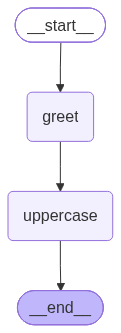

In [4]:
# 最简单的三要素示例

# 1. State：定义共享数据结构
class SimpleState(TypedDict):
    name: str      # 记录用户name
    greeting: str  # 记录生成的问候语

# 2. Node：定义处理逻辑
# node 1：生成问候语的节点
def greet_node(state: SimpleState):
    """接收name, 生成greeting"""
    print(f"greet_node is receiving name: {state['name']}")
    return {"greeting": f"Hello, {state['name']}!"}

# node 2：转大写
def uppercase_node(state: SimpleState):
    """将greeting转为大写"""
    print(f"uppercase_node is receiving greeting: {state['greeting']}")
    return {"greeting": state["greeting"].upper()}

# 3. Edge：编排执行顺序
graph_builder = StateGraph(SimpleState)           # 1. 用State创建图

graph_builder.add_node("greet", greet_node)       # greet节点
graph_builder.add_node("uppercase", uppercase_node)  # uppercase节点

graph_builder.add_edge(START, "greet")            # START --> greet
graph_builder.add_edge("greet", "uppercase")      # greet --> uppercase
graph_builder.add_edge("uppercase", END)          # uppercase --> END

graph = graph_builder.compile()                   # 4.编译成可执行图
display(Image(graph.get_graph().draw_mermaid_png()))

测试一下（注意：调用Graph必须传入初始化的State）：


In [5]:
# 执行
result = graph.invoke({"name": "World"})
print(f"结果：{result['greeting']}")

greet_node is receiving name: World
uppercase_node is receiving greeting: Hello, World!
结果：HELLO, WORLD!


## 1.2 State（状态）

State是图的共享内存，贯穿整个执行过程。

* State定义Graph中的数据字段
* 每个Node都可以获取State数据、更新的State数据（返回要更新的字段值即可）

而Node返回数据后State的更新处理方式取决于Reducers，而且State中的每个字段都有自己的Reducer。


### 1.2.1 默认Reducer

需要注意的是：如果字段没有指定Reducer，那默认的Reducer行为就是**覆盖**。

也就是说：如果多个Node都更新了State中的同一个字段，默认情况下后执行的Node将覆盖前面Node的更新结果。例如：


In [6]:
# 1. State：定义共享数据结构，这里采用默认Reducer
class DefaultReducerState(TypedDict):
    val: str

# 2. Node：定义处理逻辑
def node_1(state: DefaultReducerState):
    print(f"node_1 is receiving val: {state['val']}")
    return {"val": "node_1"}

def node_2(state: DefaultReducerState):
    print(f"node_2 is receiving val: {state['val']}")
    return {"val": "node_2"}

# 3. Edge：编排执行顺序
default_reducer_graph = (
    StateGraph(DefaultReducerState)          # 1.用State创建图
    .add_node("node_1", node_1)              # 2.注册节点
    .add_node("node_2", node_2)
    # 3.创建edge，连接各个节点
    .add_edge(START, "node_1")               # START -> node_1
    .add_edge("node_1", "node_2")            # node_1 -> node_2
    .add_edge("node_2", END)                 # node_2 -> END
    .compile()                               # 4.编译成可执行图
)

result = default_reducer_graph.invoke(DefaultReducerState(val="default"))
print(result)

node_1 is receiving val: default
node_2 is receiving val: node_1
{'val': 'node_2'}


上案例中每个Node都在修改State的`val`字段，但最终`val`只记录了最后一次的值。这就是默认的Reducer行为。

结果示例：
```
node_1 is receiving val: default
node_2 is receiving val: node_1
{'val': 'node_2'}
```


### 1.2.2 自定义Reducer

通过前面的例子我们就能看到默认的Reducer效果了。

如果我们不希望覆盖，则需要自定义Reducer，需要用到Annotated来定义：

* `Annotated[type, reducer]`


In [7]:
from operator import add
from typing import Annotated, TypedDict, List

class CustomReducerState(TypedDict):
    count: int                              # 这个字段没有定义Reducer，也就是默认会覆盖旧值
    nodes: Annotated[List[str], add]        # 这里使用add作为Reducer，也就是会拼接结果

# 2. Node：定义处理逻辑
def node_1(state: CustomReducerState):
    print(f"node_1 is receiving count: {state['count']}")
    return {"count": 1, "nodes": ["node_1"]}  # 直接修改nodes值，不用自己拼接

def node_2(state: CustomReducerState):
    print(f"node_2 is receiving count: {state['count']}")
    return {"count": 2, "nodes": ["node_2"]}  # 直接修改nodes值，不用自己拼接

# 3. Edge：编排执行顺序
custom_reducer_graph = (
    StateGraph(CustomReducerState)           # 1.用State创建图
    .add_node("node_1", node_1)              # 2.注册节点
    .add_node("node_2", node_2)
    # 3.创建edge，连接各个节点
    .add_edge(START, "node_1")               # START -> node_1
    .add_edge("node_1", "node_2")            # node_1 -> node_2
    .add_edge("node_2", END)                 # node_2 -> END
    .compile()                               # 4.编译成可执行图
)

result = custom_reducer_graph.invoke(CustomReducerState(count=0, nodes=[]))
print(result)

node_1 is receiving count: 0
node_2 is receiving count: 1
{'count': 2, 'nodes': ['node_1', 'node_2']}


可以看到，尽管Node中每次都是直接修改State的nodes字段，但最终由于使用了add这个Reducer，它会把nodes的初始值与新值拼接，类似于：

```python
nodes = []
nodes = nodes + ['node1'] + ['node2']
```

结果示例：
```
node_1 is receiving count: 0
node_2 is receiving count: 1
{'count': 2, 'nodes': ['node_1', 'node_2']}
```


## 1.3 Edge（边）

Edge定义节点的执行顺序。LangGraph提供两种Edge：

| 边类型 | 方法 | 说明 |
|--------|------|------|
| 普通边 (Normal Edge) | `add_edge(node_a, node_b)` | 固定流向：A执行完一定到B |
| 条件边 (Conditional Edge) | `add_conditional_edges(node_a, router, mapping)` | router的返回值决定下一节点 |


### 1.3.1 Normal Edge

普通边连接的两个节点流向是固定的，前一个节点执行完一定会执行后一个节点。不同之处在于节点之间是串行还是并行：

* **串行**：整个工作流只有一条路径，路径中的节点按照顺序依次执行
* **并行**：整个工作流由多条路径，不同路径可以同时执行

上节我们演示的就是串行方式，本节课我们再来看看并行方式，结构如图：

```
      ┌──> b ──┐
a ────┤        ├────> d
      └──> c ──┘
```


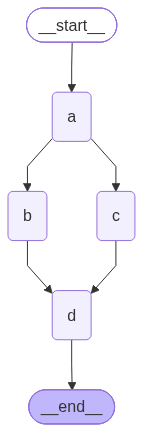

In [8]:
class ParallelState(TypedDict):
    nodes: Annotated[list[str], add]

def node_a(state: ParallelState):
    print(f"node_a is running, nodes: {state['nodes']}")
    return {"nodes": ["a"]}

def node_b(state: ParallelState):
    print(f"node_b is running, nodes: {state['nodes']}")
    return {"nodes": ["b"]}

def node_c(state: ParallelState):
    print(f"node_c is running, nodes: {state['nodes']}")
    return {"nodes": ["c"]}

def node_d(state: ParallelState):
    print(f"node_d is running, nodes: {state['nodes']}")
    return {"nodes": ["d"]}

parallel_graph = (
    StateGraph(ParallelState)
    .add_node("a", node_a)
    .add_node("b", node_b)
    .add_node("c", node_c)
    .add_node("d", node_d)
    .add_edge(START, "a")   # start -> a
    .add_edge("a", "b")     # a -> b
    .add_edge("a", "c")     # a -> c
    .add_edge("b", "d")     # b -> d
    .add_edge("c", "d")     # c -> d
    .add_edge("d", END)     # d -> end
    .compile()
)

display(Image(parallel_graph.get_graph().draw_mermaid_png()))

测试运行：


In [9]:
result = parallel_graph.invoke(ParallelState(nodes=[]))
print(result)

node_a is running, nodes: []
node_b is running, nodes: ['a']
node_c is running, nodes: ['a']
node_d is running, nodes: ['a', 'b', 'c']
{'nodes': ['a', 'b', 'c', 'd']}


能发现，b和c确实是并行运行，因为node_b和node_c接收到了相同的参数。

结果示例：
```
node_a is running, nodes: []
node_b is running, nodes: ['a']
node_c is running, nodes: ['a']
node_d is running, nodes: ['a', 'b', 'c']
{'nodes': ['a', 'b', 'c', 'd']}
```


### 1.3.2 Conditional Edge

条件边的添加方式如下：

```python
add_conditional_edges(node_a, router, mapping)
```

接收三个参数：

* `node_a`：是当前节点
* `router`：路由函数，逻辑自定义，它的返回值默认就是下个节点的名字。
* `mapping`：如果 `router` 返回值与下个节点名不一样，可以用 `mapping` 定义返回值与下个节点名字的映射关系

`router` 可以根据情况返回不同的结果，但一次只能有一个结果。也就是说 Conditional Edge 连接的多个节点有且只有1个会成为 `next_node`。

例如，我们实现一个成绩判定的 Graph，用户输入一个分数，我们根据分数判断走哪个节点：

* 大于60，走成功节点
* 小于60，走失败节点


In [10]:
# 条件边示例：根据state决定走哪条路
class RouteState(TypedDict):
    score: int
    result: str

def scorer(state: RouteState):
    score = int(input("请输入分数:"))
    print(score)
    return {"score": score}  # 模拟评分

def pass_node(state: RouteState):
    return {"result": "通过！"}

def fail_node(state: RouteState):
    return {"result": "不通过"}

def router(state: RouteState) -> Literal["pass", "fail"]:
    """根据score决定下一节点"""
    if state["score"] >= 60:
        return "pass"
    return "fail"

condition_graph = (
    StateGraph(RouteState)                       # 1.创建Graph
    # 2.添加节点
    .add_node("scorer", scorer)                  # 打分节点
    .add_node("pass", pass_node)                 # 成功节点
    .add_node("fail", fail_node)                 # 失败节点
    # 3.添加Edge
    .add_edge(START, "scorer")                   # start -> scorer
    .add_conditional_edges("scorer", router)     # scorer -> conditional_edge(router) 这一块代码实现下一节点的判断
    .add_edge("pass", END)                       # pass -> end
    .add_edge("fail", END)                       # fail -> end
    .compile()
)

# 注意：运行时需要交互输入分数，例如输入 95
# result = condition_graph.invoke({"score": 0, "result": ""})
# print(f"score={result['score']} -> {result['result']}")
print("条件边Graph已构建完成（运行时请取消注释并输入分数测试）")

条件边Graph已构建完成（运行时请取消注释并输入分数测试）


### 1.3.3 Command实现条件分支

如果不想编写Conditional Edge，也可以在Node中直接返回下个节点信息。

但是，由于Node必须返回对State的更新，而没有条件边就需要返回下个节点的名字。函数返回值只能有一个。所以LangGraph就提供了Command API，用Command来指定下个节点以及要更新的字段。

示例：

```python
def node_a(state: State) -> Command[Literal['node_b', 'node_c']]:
    # ...
    return Command(
        update={"k":"v"},
        goto="node_b"
    )
```

其中：

* `update`：用来指定要更新的State字段
* `goto`：用来指定下个节点

还是刚才的例子，我们用Command来实现：


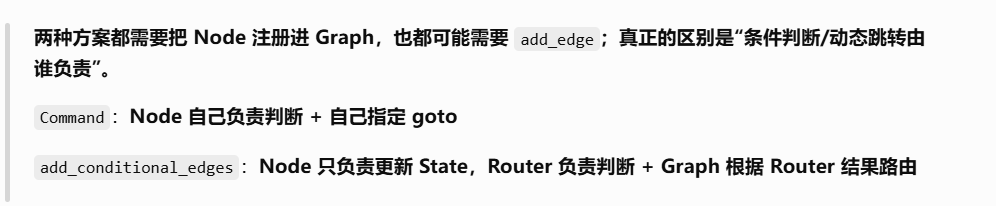



###### **_如果你的需求是“根据运行时条件决定下一个 Node”，而又不使用 Command，通常就需要 add_conditional_edges()_**


In [11]:
# 在Node中基于Command实现条件分支
# 当需要既更新状态又决定跳转时，用 Command；如果只需要路由、不需要更新状态，更推荐传统的 add_conditional_edges


# 1.定义state  TypedDict 类型提示 告诉RouteState应该是一个字典
class RouteState(TypedDict):
    score: int
    result: str

# 定义scorer Node 获取分数 → 判断是否及格 → 更新 State → 决定下一个 Node
def scorer(state: RouteState) -> Command[Literal["fail", "pass"]]:
    # 获取用户输入
    score = int(input("请输入分数:"))
    # 根据分数决定下一节点
    next_node = "pass" if score >= 60 else "fail"
    # 返回Command “告诉 LangGraph 接下来怎么执行”的指令
    return Command(
        update={"score": score},   # 通过update更新State字段
        goto=next_node             # 通过goto指定下个Node
    )

def pass_node(state: RouteState):
    return {"result": "通过！"}

def fail_node(state: RouteState):
    return {"result": "不通过"}

# add_node：告诉 Graph “有哪些节点可以执行”。

# add_edge：告诉 Graph “节点执行完以后，固定往哪里走”  Command 负责“这个 Node 执行完后，我动态决定去哪”。add_edge 负责“Graph 中两个节点之间存在什么固定连接”。

command_condition_graph = (
    StateGraph(RouteState)                   # 1.创建Graph
    # 2.添加节点
    .add_node("scorer", scorer)              # 打分节点
    .add_node("pass", pass_node)             # 成功节点
    .add_node("fail", fail_node)             # 失败节点
    # 3.添加Edge
    .add_edge(START, "scorer")               # start -> scorer
    .add_edge("pass", END)                   # pass -> end
    .add_edge("fail", END)                   # fail -> end
    .compile()
)

# 注意：运行时需要交互输入分数
# result = command_condition_graph.invoke({"score": 0, "result": ""})
# print(f"score={result['score']} -> {result['result']}")
print("Command条件分支Graph已构建完成（运行时请取消注释并输入分数测试）")

Command条件分支Graph已构建完成（运行时请取消注释并输入分数测试）


# 2. LangGraph构建Agent

学会了用LangGraph的基本概念，以及如何创建Graph，接下来我们就可以用LangGraph从零构建一个Agent了。


## 2.1 基础LLM调用工作流

让我们先从最基本的LLM调用开始，先不要工具。

工作流是这样的：

`START --> 调用LLM --> END`
 '流程固定：START → llm → END，只有一条路，没有任何判断或选择' 因此不需要Command或者add_condition_edge判断下一分支


In [12]:
# 1. 先初始化一个模型
llm = init_chat_model("deepseek-chat")

# 2. 定义State，记录用户输入和LLM返回的结果
class SimpleAgentState(TypedDict):
    user_input: str
    result: str
# 使用 TypedDict 定义图的状态结构。
# user_input：存放用户输入的问题。
# result：存放 LLM 返回的回答。
# 在整个图执行过程中，状态会在节点之间传递和更新。

# 3. 定义LLM调用Node
def call_llm(state: SimpleAgentState):
    # 调用LLM, 得到结果
    response = llm.invoke(state['user_input'])
    # 更新state
    return {"result": response.content}
# call_llm 是图中的一个节点（Node）。
# 接收当前状态 state。
# llm.invoke(state['user_input'])：把用户输入发给大模型，得到 AIMessage 对象。
# response.content：取出模型返回的文本内容。
# return {"result": ...}：返回一个字典，表示要更新状态中的 result 字段（LangGraph 会自动把这个更新合并进全局状态）。

# 4. 创建Graph
llm_graph = (
    StateGraph(SimpleAgentState) # ① 创建图，指定状态类型
    .add_node("llm", call_llm)   # ② 添加节点，名字叫 "llm"，对应函数 call_llm
    .add_edge(START, "llm")      # ③ 添加边：从 START 指向 "llm" 节点
    .add_edge("llm", END)        # ④ 添加边：从 "llm" 指向 END
    .compile()                   # ⑤ 编译成可执行的图
)

# 执行图并打印结果
result = llm_graph.invoke(SimpleAgentState(user_input="你好", result=""))
print(result)

{'user_input': '你好', 'result': '你好呀！👋 很高兴见到你！\n\n我是DeepSeek，你的AI助手，随时准备帮你解答问题、聊天或者处理各种任务。不管是学习、工作还是生活中的疑惑，都可以来找我聊一聊。\n\n今天有什么我可以帮你的吗？或者只是想随便聊聊天也完全OK！😊'}


## 2.2 消息历史

目前的Graph中，State比较简单，只记录了两个值：

* `user_input`：一次用户输入
* `result`：一次LLM结果

然后实际在复杂的Agent中，用户会多次与LLM交互，还有工具调用，产生大量的历史消息，这些消息都需要记录下来。因此，我们的State需要重新设计。


### 2.2.1 自定义消息历史State

在之前学习LangChain时我们知道，Agent交互时的消息类型有很多：SystemMessage、AIMessage、HumanMessage、ToolMessage等。而这些消息都有一个共同的父类：BaseMessage。

因此，我们可以在State中定义一个字段，类型为 `list[BaseMessage]`。但这还不够，由于要不断添加新的消息到这个list，所以还需要一个Reducer，而LangChain正好提供了这样的一个Reducer：`add_messages`


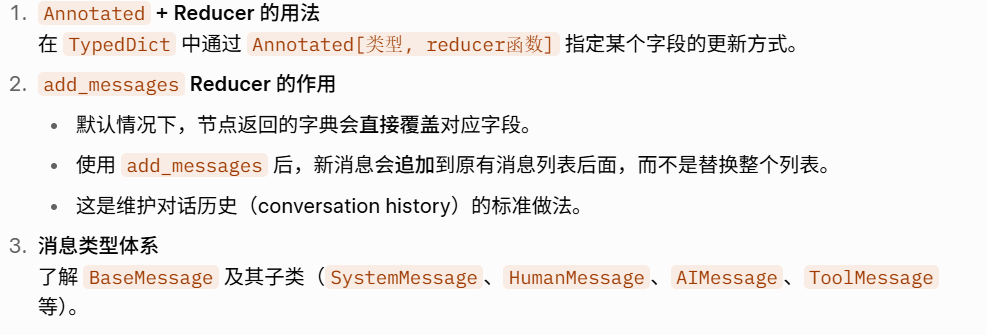


In [13]:
# 如何用 add_messages 来实现消息列表的累积追加，而不是覆盖

from langgraph.graph.message import add_messages  # 从 LangGraph 导入官方提供的 add_messages 函数（它是一个 Reducer）
from langchain_core.messages import (
    BaseMessage, SystemMessage, HumanMessage, ToolMessage
) # 导入消息相关的基类和常用消息类型  BaseMessage是所有消息的父类  SystemMessage、HumanMessage、ToolMessage 分别代表系统提示、用户消息、工具返回消息


# 定义图的状态结构。
# messages 字段的类型是 list[BaseMessage]。
# 通过 Annotated[..., add_messages] 告诉 LangGraph：
# 当有节点返回 {"messages": 新消息} 时，不要覆盖原列表，而是调用 add_messages 把新消息追加进去。
class MessageAgentState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

# add_messages这个Reducer的效果就是不断累积消息，形成Message列表：
messages = [SystemMessage(content="你是一个热心助人的AI助手，你的名字叫武藏")]
messages = add_messages(messages, HumanMessage(content="你好，你是谁？"))
print(messages)

[SystemMessage(content='你是一个热心助人的AI助手，你的名字叫武藏', additional_kwargs={}, response_metadata={}, id='cb3a2ca1-7d28-47ad-ab16-fc9c6093f485'), HumanMessage(content='你好，你是谁？', additional_kwargs={}, response_metadata={}, id='86af621b-a94b-41dd-be47-16ff77799257')]


来看一个完整示例：


In [14]:
from langgraph.graph.message import add_messages

class MessageAgentState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

# 上述部分：定义状态，核心是 messages 字段。使用 Annotated + add_messages，保证每次节点返回新消息时，是追加而不是覆盖 自动调用add_message

# 1.先初始化一个模型
llm = init_chat_model("deepseek-chat")

# 2.定义LLM调用Node
def call_llm(state: MessageAgentState):
    # 调用llm，得到结果  LLM 返回一条 AIMessage
    response = llm.invoke(state['messages'])
    # 更新state 返回 {"messages": [response]}，由 add_messages 自动追加到历史后面
    return {"messages": [response]}

# 3.创建Graph  构建最简单的线性图：START → llm → END
llm_graph = (
    StateGraph(MessageAgentState)
    .add_node("llm", call_llm)
    .add_edge(START, "llm")
    .add_edge("llm", END)
    .compile()
)

# 传入初始消息列表（通常包含 SystemMessage + HumanMessage），执行图，最终得到包含 AI 回复的完整消息列表
result = llm_graph.invoke({"messages": messages})
print(result)

{'messages': [SystemMessage(content='你是一个热心助人的AI助手，你的名字叫武藏', additional_kwargs={}, response_metadata={}, id='cb3a2ca1-7d28-47ad-ab16-fc9c6093f485'), HumanMessage(content='你好，你是谁？', additional_kwargs={}, response_metadata={}, id='86af621b-a94b-41dd-be47-16ff77799257'), AIMessage(content='你好呀！我是武藏，你的AI助手。很高兴见到你！有什么我可以帮忙的吗？不管是解答问题、提供建议，还是陪你聊聊，我都会尽力而为哦！😊', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 38, 'prompt_tokens': 21, 'total_tokens': 59, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 21}, 'model_provider': 'deepseek', 'model_name': 'deepseek-v4-flash', 'system_fingerprint': 'a26a7955944dc5c60445bff77fac9c8e', 'id': '1f7aed12-3bac-4b36-a33e-35474005a90e', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a0278a-0c7c-7a12-aaf3-b28cb2e817f6-0', tool_calls=[], invalid_tool_calls=[], usage_me

怎么样，熟悉的味道又回来了，这个返回值是不是跟LangChain的Agent返回值一模一样呢？

没错，因为LangChain的 `create_agent` 正是基于LangGraph实现的~

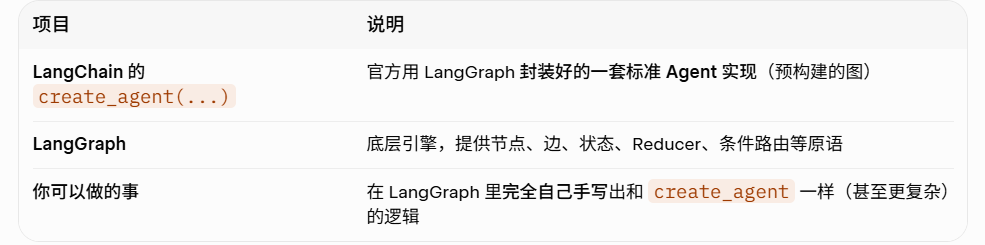

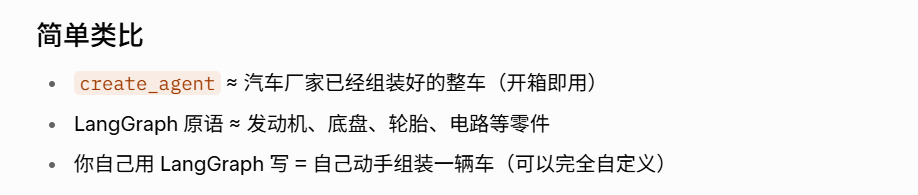

###### **_create_agent 是 LangGraph 的“官方成品模板”，而 LangGraph 本身允许你从零开始自定义实现任何你想要的 Agent 流程_**




**_区别：Langchain与LangGraph_**
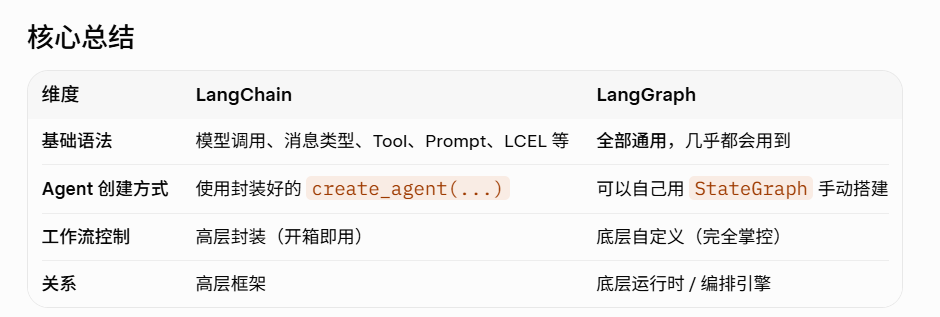



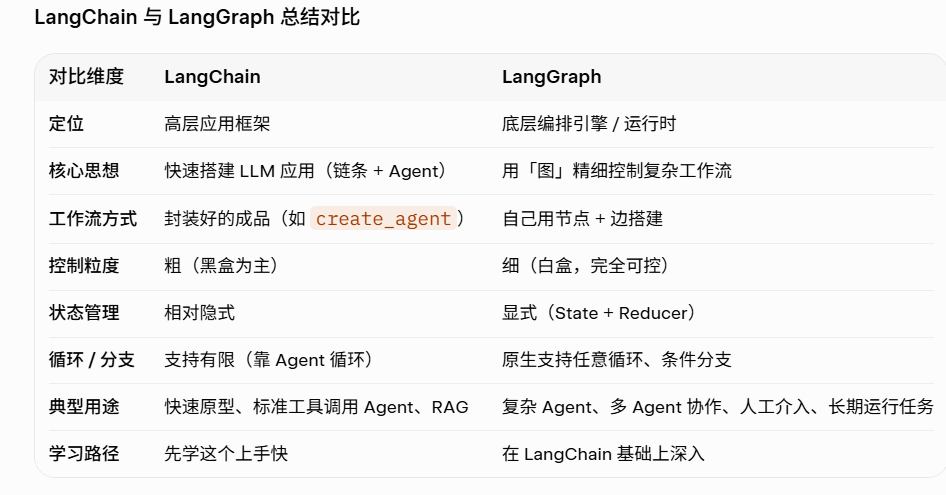

### 2.2.2 默认的MessagesState

事实上，记录Agent消息的场景非常常见，所以LangGraph中还提供了一个默认的State，专门用来记录消息历史，叫做 `MessagesState`：

```python
class MessagesState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]
```

可以看到其结构与我们自定义的非常相似，只是消息类型改成了 `AnyMessage`，它可以看做是所有消息的统一类型。

所以，如果只是为了记录消息历史，我们可以不用定义State了，直接用 `MessagesState`：


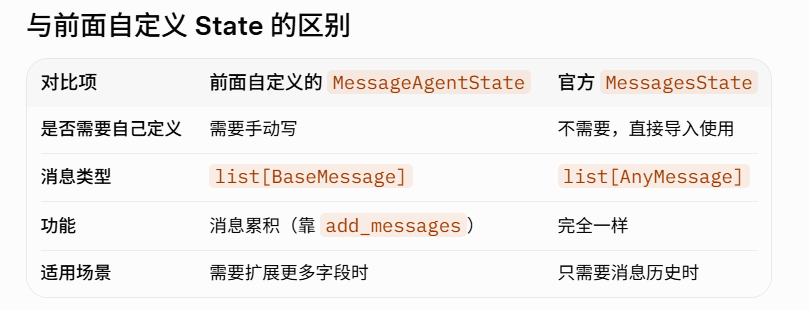

###### **_前面我们手动写 MessageAgentState 是为了理解原理。_**
###### **_官方提供的 MessagesState 就是把这个最常见的需求封装好了，让你少写几行代码。_**
###### **_本质功能完全一样，只是官方版本更方便、类型更规范（用了 AnyMessage）。_**
######
###### **_当你的状态只需要消息历史时，优先使用 MessagesState；需要额外字段时，再自己定义或继承它_**




理解 LangGraph与Langchain关系

###### LangGraph
######    ↓
###### 提供 Graph / State / Node / Edge / Agent Loop 等底层编排能力
######    ↓
###### 形成一个可执行的 Agent Graph
######    ↓
###### LangChain
######    ↓
###### create_agent(...)
######    ↓
###### 帮用户方便地创建这个标准 Agent

In [15]:
# 导入官方提供的消息累加器 add_messages 和默认状态 MessagesState
from langgraph.graph.message import add_messages, MessagesState

# 1.先初始化一个模型
llm = init_chat_model("deepseek-chat")

# 2.定义LLM调用Node call_llm 是业务处理节点
def call_llm(state: MessagesState):
    # 调用llm，得到结果
    response = llm.invoke(state['messages'])
    # 更新state
    return {"messages": [response]}

# 3.创建Graph 构建一条最简单的线性流程：START → llm → END 构建工作流
llm_graph = (
    StateGraph(MessagesState)   # ① 创建图，并指定状态类型为 MessagesState
    .add_node("llm", call_llm)  # ② 添加一个名为 "llm" 的节点，对应函数 call_llm
    .add_edge(START, "llm")     # ③ 添加边：从起点 START 指向 "llm" 节点
    .add_edge("llm", END)       # ④ 添加边：从 "llm" 节点指向终点 END
    .compile()                  # ⑤ 编译图，生成可执行的对象
)

result = llm_graph.invoke({"messages": [HumanMessage(content="你好")]})
print(result)

{'messages': [HumanMessage(content='你好', additional_kwargs={}, response_metadata={}, id='7b0bc307-454d-40a7-905a-cad856d88647'), AIMessage(content='你好呀！😊 很高兴见到你！我是DeepSeek，你的AI助手。无论你有什么问题、需要帮助，还是只是想聊聊天，我都在这儿！\n\n今天有什么可以帮你的吗？学习、工作、生活小问题，还是想要一些有趣的想法和推荐？别客气，尽管开口吧！✨', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 65, 'prompt_tokens': 5, 'total_tokens': 70, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 5}, 'model_provider': 'deepseek', 'model_name': 'deepseek-v4-flash', 'system_fingerprint': 'a26a7955944dc5c60445bff77fac9c8e', 'id': 'ba02ba6d-988c-441b-98a5-fb31600426e1', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a02828-f852-7c32-87fe-1309325110b2-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 5, 'output_tokens': 65, 'total_tokens': 70, 'input_token_details': {

## 2.3 会话记忆

有了历史并不等于有记忆，记忆必须基于会话id（`thread_id`）来分别管理会话历史。这就要靠LangGraph中的 `Checkpointer` 来实现了。

之前在LangChain中我们就是导入的LangGraph提供的 `Checkpointer` 来实现记忆的，这里也一样。我们用默认的 `InMemorySaver` 来演示。

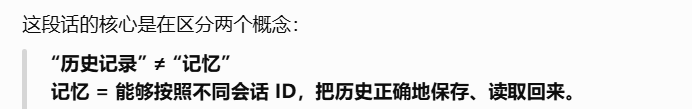


#### **thread_id 决定“记谁的”，Checkpointer 负责“存下来并找回来”，Graph/Agent 负责“拿这些状态继续运行”**


In [16]:
# 从 LangGraph 提供的 Checkpoint 模块中，导入一个叫 InMemorySaver 的 Checkpointer
from langgraph.checkpoint.memory import InMemorySaver

# 1.先初始化一个模型
llm = init_chat_model("deepseek-chat")

# 2.定义LLM调用Node
def call_llm(state: MessagesState):
    # 调用llm，得到结果
    response = llm.invoke(state['messages'])
    # 更新state
    return {"messages": [response]}

# 3.创建Graph
memory_graph = (
    StateGraph(MessagesState)
    .add_node("llm", call_llm)
    .add_edge(START, "llm")
    .add_edge("llm", END)
    .compile(checkpointer=InMemorySaver())  # 注意，在compile时指定Checkpointer  这个 Graph 在运行过程中，要启用 Checkpointer  把状态保存/恢复能力也接入这个Graph
)

# 4.测试
# 依然要通过config中的thread_id来区分不同会话 告诉 Checkpointer：这次 Graph 执行属于哪个会话
config = {"configurable": {"thread_id": "1"}}

result = memory_graph.invoke(
    {"messages": [HumanMessage(content="你好，我是虎哥")]},
    config
)
result = memory_graph.invoke(
    {"messages": [HumanMessage(content="我是谁？")]},
    config
)
print(result)

{'messages': [HumanMessage(content='你好，我是虎哥', additional_kwargs={}, response_metadata={}, id='28bf2fc9-4312-4bc3-a26e-852060c041f4'), AIMessage(content='你好虎哥！👋 很高兴见到你！有什么我可以帮你的吗？无论是闲聊、解答问题，还是需要一些建议，我随时待命！😄', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 35, 'prompt_tokens': 9, 'total_tokens': 44, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 9}, 'model_provider': 'deepseek', 'model_name': 'deepseek-v4-flash', 'system_fingerprint': 'a26a7955944dc5c60445bff77fac9c8e', 'id': 'ac142a87-0ca3-4725-8bfe-88a5bed0c85a', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a02829-0c17-7593-8fb9-95a75716ffc9-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 9, 'output_tokens': 35, 'total_tokens': 44, 'input_token_details': {'cache_read': 0}, 'output_token_details': {}}), HumanMess

## 2.4 带工具调用的LLM工作流

Agent通常是绑定了工具的LLM。它没有固定的工作流，而是采用ReAct行为模式：
###### **_ReAct Agent = LLM 不再“一次性回答问题”，而是让 LLM 自己决定“下一步是思考、调用什么工具、拿到结果后再思考，还是直接回答”_**

1. 把问题交给LLM处理 (Reasoning)
   a. 判断是否需要调用工具
   b. 要调用哪个工具
2. 调用工具 (Action)
3. 拿到工具结果，返回结果给LLM，判断是否能回答问题 (回到1)
4. 生成响应，结束

如果我们把“调用LLM”、“工具执行”，都看做是Node(流程中执行的一个步骤)，那节点的流转就是由LLM控制的，动态循环的过程。


### 2.4.1 定义Tool


In [17]:
from langchain.tools import tool

# ===== Step 1: 准备工具和模型 =====
# 工具
@tool
def get_weather(city: str) -> str:
    """获取城市天气"""
    weather_data = {
        "北京": "晴天 25度",
        "上海": "多云 28度",
        "杭州": "小雨 22度",
    }
    return weather_data.get(city, f"未找到{city}的天气信息")

@tool
def square_root(x: float) -> str:
    """Calculate the square root of a number"""
    return str(x ** 0.5)

# 组成工具数组
tools = [get_weather, square_root]
# 组成工具名和工具的映射，方便查找工具
tools_by_name = {t.name: t for t in tools}
# 定义模型
model = init_chat_model("deepseek-chat")
# 绑定工具到模型 把工具注册/绑定到大模型上，让 LLM 知道有哪些工具可以使用
model_with_tools = model.bind_tools(tools)

print("工具和模型准备完成")
print(f"可用工具: {[t.name for t in tools]}")

工具和模型准备完成
可用工具: ['get_weather', 'square_root']


需要注意的，手动调用带工具的模型，模型会返回要执行的工具的信息，我们需要解析这些信息，拿到要调用的工具名称和参数，自己去调用。

所以，我们才在上面建立了工具name与工具的映射。

另外，等一下定义Node的时候就需要自己调用Tool。

##### **可以理解为：**
###### **_1. LangChain：你需要自己组织“调用过程”  2. LangGraph：你提前定义“框架”，LLM 动态决定“走哪条路”_**

### 2.4.2 定义Node


In [19]:
# ====== Step 2: 定义Node函数 ======
# 开始真正把 Agent 的执行逻辑拆成 LangGraph 的 Node

# llm_node：让 LLM 做决策
def llm_node(state: MessagesState):
    """LLM节点：调用模型，可以选择调用工具"""
    # 把目前为止的对话消息全部交给 LLM，让 LLM 根据上下文决定下一步做什么
    # model_with_tools 已经知道有哪些 Tool 可以调用的 LLM
    response = model_with_tools.invoke(state["messages"])
    # 这个 Node 执行完成后，要把 LLM 的响应加入 Graph 的 State 中
    return {"messages": [response]}

# tool_node：真正执行工具 LLM 说要调用什么工具，我就真正执行什么工具
def tool_node(state: MessagesState):
    """工具节点：执行LLM要求的工具调用"""

    # 消息列表中的最后一条消息 可能获取到LLM要求调用哪些工具
    last_message = state["messages"][-1]
    # 所有工具执行后的结果
    results = []
    # AI可能一次返回多个工具调用，所以需要循环处理，再收集结果 遍历 LLM 返回的所有工具调用请求
    for tool_call in last_message.tool_calls:
        # 根据工具名称找到工具
        tool = tools_by_name[tool_call["name"]]
        # 工具执行
        result = tool.invoke(tool_call["args"])
        # LLM需要知道这个结果是哪个工具返回的
        results.append(ToolMessage(
            content=str(result),
            tool_call_id=tool_call["id"]
        ))
    # 把工具执行结果写回 Graph State 的 messages
    return {"messages": results}

# should_continue：决定下一步走哪里 Tool 执行完以后，是继续调用 LLM，还是结束
def should_continue(state: MessagesState) -> Literal["tools", "__end__"]:
    """路由函数：判断下一步是继续调工具还是结束"""
    last_message = state["messages"][-1]
    # 如果包含tool_calls，则跳转到tools节点，没有则跳转到END节点
    if hasattr(last_message, 'tool_calls') and last_message.tool_calls:
        return "tools"  # 有工具调用 -> 去工具节点
    return END          # 没工具调用 -> 结束

print("Step 2 完成: Node函数已定义")

Step 2 完成: Node函数已定义


### 2.4.3 构建Graph
##### **_整体流程示意图_**
###### START → llm ──(需要工具)──→ tools ──→ llm ──→ ...
######          │
######          └──(不需要工具)──→ END

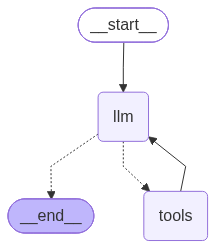

In [20]:
# ====== Step 3: 构建图 ======
# Step 1：准备 LLM + Tools
# Step 2：定义 Node + 路由函数
# Step 3：把这些 Node 连成一张图
agent_graph = (
    StateGraph(MessagesState) # 创建一个 LangGraph 图
    .add_node("llm", llm_node) # 向图中添加一个名为 "llm" 的节点，对应的处理函数是 llm_node。这个节点负责调用大语言模型（LLM），根据当前消息决定是直接回复还是调用工具
    .add_node("tools", tool_node) # 向图中添加一个名为 "tools" 的节点，对应的处理函数是 tool_node。这个节点负责真正执行工具（例如搜索、计算等），并把工具结果写回状态。
    .add_edge(START, "llm")
    .add_conditional_edges("llm", should_continue)
    .add_edge("tools", "llm")  # 工具执行后回到LLM，形成循环
    .compile()
)

display(Image(agent_graph.get_graph().draw_mermaid_png()))

测试：


In [21]:
# ===== Step 4: 测试 =====
print("测试1: 不需要工具调用\n")
result = agent_graph.invoke({
    "messages": [HumanMessage(content="你好")]
})
for m in result['messages']:
    m.pretty_print()

测试1: 不需要工具调用

================================ Human Message =================================

你好
================================== Ai Message ==================================

你好！有什么我可以帮助你的吗？


In [24]:
print("测试2: 需要工具调用\n")
result = agent_graph.invoke({
    "messages": [HumanMessage(content="成都今天天气怎么样？")]
})
for m in result['messages']:
    m.pretty_print()

测试2: 需要工具调用

================================ Human Message =================================

成都今天天气怎么样？
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_00_djU7s4c0pS0K40PMCbgB2666)
 Call ID: call_00_djU7s4c0pS0K40PMCbgB2666
  Args:
    city: 成都
================================= Tool Message =================================

未找到成都的天气信息
================================== Ai Message ==================================

抱歉，我目前无法获取到成都的天气信息。这可能是因为天气数据源暂时不可用，或者该城市的信息暂未收录。

建议您可以通过以下方式获取成都的天气：
- **手机天气应用**（如系统自带天气、墨迹天气等）
- **气象网站**（如中国天气网、天气通等）
- **搜索引擎** 搜索"成都天气"

如果您需要，我也可以帮您查询其他城市的天气情况，或者尝试其他方式获取信息。有什么我可以帮您的吗？


## 2.5 Runtime Context

在LangGraph中同样支持Runtime Context功能，方式也完全一样：

* 定义ContextSchema
* 创建Graph时指定state、context_schema、store等Runtime

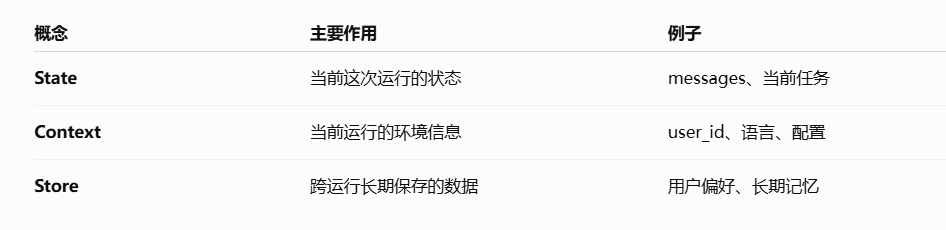


In [25]:
# 这一块代码演示的是如何定义 Context → 把 Context 注册到 Graph → Node 中读取 Context → 调用 Graph 时传入 Context

from pydantic.dataclasses import dataclass # 导入这个包 它的作用是方便你定义一个结构化的数据对象 定义一个context数据结构

# 定义一个ContextSchema结构 用来描述运行时上下文（Runtime Context）里有哪些字段

@dataclass # 自动为这个类生成 __init__、__repr__、__eq__ 等方法，让类变成一个轻量级的数据容器，写起来非常简洁
class ContextSchema:
    reasoning: str = "enable"  # 定义一个reasoning字段是否开启思考模式

# 1.先初始化一个模型，比如DeepSeek
llm = init_chat_model("deepseek-chat")

# 2.定义LLM调用Node Node同时获得State+Runtime
def call_llm(state: MessagesState, runtime: Runtime[ContextSchema]):
    # 调用llm，得到结果
    response = llm.invoke(
        state['messages'],
        # 通过thinking参数控制是否开启思考模式（示例，实际参数视模型而定） Context 可以作为 Node 执行时的运行参数
        # extra_body={"thinking": {"type": runtime.context.reasoning}}
    )
    print("调用llm")
    print(f"当前context.reasoning = {runtime.context.reasoning}")
    # 更新state
    return {"messages": [response]}

# 3.创建Graph
context_graph = (
    StateGraph(MessagesState, context_schema=ContextSchema)
    .add_node("llm", call_llm)
    .add_edge(START, "llm")
    .add_edge("llm", END)
    .compile()
)

# 4.调用Graph，传递context信息 调用已经编译好的图（context_graph），并在这次运行中传入 Runtime Context 信息
result = context_graph.invoke(
    {"messages": [HumanMessage(content="你是谁？")]},
    context={"reasoning": "disabled"}  # 用字典形式传入：reasoning 字段的值设为 "disabled"，表示这次运行关闭思考模式。图内部的节点可以通过 runtime.context.reasoning 读取到这个值，从而决定是否开启思考链等逻辑。
)
print(result)

调用llm
当前context.reasoning = disabled
{'messages': [HumanMessage(content='你是谁？', additional_kwargs={}, response_metadata={}, id='0cda1994-cdc5-40a3-b900-0b72568dfdde'), AIMessage(content='你好呀！我是DeepSeek，由深度求索公司创造的AI助手！😊\n\n让我简单介绍一下自己：\n\n**我的特点：**\n- 🆓 **完全免费** - 没有任何收费计划，可以放心使用\n- 📚 **超大上下文** - 支持1M上下文，可以一次性处理像《三体》三部曲那样的长篇内容\n- 📎 **文件上传** - 支持上传图片、PDF、Word、Excel、PPT等文件，并读取其中的文字信息\n- 🌐 **联网搜索** - 需要时可以手动开启联网功能获取最新信息\n- 🎤 **语音输入** - App端支持语音输入，更方便交流\n\n**我的能力：**\n- 可以回答各种问题，帮你解决疑惑\n- 帮你处理文档、分析数据\n- 创作文字内容、翻译、编程辅助等等\n\n**我的版本：** 我是DeepSeek最新版模型（具体版本号可以查阅官方文档和公告）\n\n有什么我可以帮你的吗？无论是学习、工作还是生活上的问题，都欢迎随时问我！💪', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 225, 'prompt_tokens': 6, 'total_tokens': 231, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 6}, 'model_provider': 'deepseek', 'model_name': 'deepseek-v4-f

## 2.6 节点缓存(Node Cache)

LangGraph还提供了节点级别的缓存功能。当请求进入节点时，会根据节点输入的参数生成key，以key和节点的输出建立缓存。如果下次key命中，则直接返回结果而不用再执行该节点的逻辑。

要使用节点缓存需要两步：

* 在编译Graph时指定缓存实现方式，LangGraph提供了 `InMemoryCache`、`RedisCache`、`SqliteCache`
* 为节点指定缓存策略。每个缓存策略支持：
  * `key_func`：函数，用于根据节点的输入生成缓存键，默认为带有pickle的输入参数的hash值。
  * `ttl`：缓存的有效时间，以秒为单位。如果没有指定，缓存将永远不会过期。



###### **_Node Cache 命中 = 跳过这个 Node 的实际执行，从而节省这个 Node 的计算/模型调用成本；并不意味着整个 LangGraph Agent 不消耗 Token**_

######  **_Node Cache 是 LangGraph 提供的性能优化机制：根据 Node 的输入生成 Cache Key，如果之后相同输入命中缓存，就直接返回之前的 Node 输出，不再执行这个 Node_**


In [26]:
from typing import Any # 导入 Any 是为了给 my_cache_key 函数的 *args 和 **kwargs 添加「接受任意类型」的类型注解
from langgraph.cache.memory import InMemoryCache  # 把 Cache 存在当前程序的内存中
from langgraph.types import CachePolicy # 导入节点缓存策略，这个 Node 怎么生成 Cache Key？缓存多久？

# 1.先初始化一个模型
llm = init_chat_model("deepseek-chat")

# 2.定义LLM调用Node
def call_llm(state: MessagesState):
    # 调用llm，得到结果
    response = llm.invoke(state['messages'])
    print("调用llm")
    # 更新state
    return {"messages": [response]}

# 自定义 Cache Key 生成函数
# 当 LangGraph 要执行带有 cache_policy 的节点时，会先调用这个函数，根据当前节点的输入生成一个 key。如果这个 key 之前已经出现过，就直接返回缓存结果，跳过节点的实际执行
def my_cache_key(*args: Any, **kwargs: Any) -> str | bytes:
    """把用户的消息作为key，消息一样则缓存命中"""
    msgs = args[0]['messages']
    return msgs[0].content if msgs and len(msgs) > 0 else "0"

# 3.创建Graph 用来演示 Node Cache 功能的工作流
cache_graph = (
    StateGraph(MessagesState)
    # 只有配置了 cache_policy 的节点才会在执行前根据 key_func 生成缓存键并决定是否跳过执行，未配置的节点则每次都会正常执行
    .add_node("llm", call_llm, cache_policy=CachePolicy(key_func=my_cache_key))
    .add_edge(START, "llm")
    .add_edge("llm", END)
    .compile(cache=InMemoryCache())
)

print("缓存Graph构建完成")

缓存Graph构建完成


In [27]:
# 4.测试
print("第一次调用：")
result = cache_graph.invoke(
    {"messages": [HumanMessage(content="你好")]}
)
print(result)

print("\n第二次调用（应命中缓存，不再打印'调用llm'）：")
result = cache_graph.invoke(
    {"messages": [HumanMessage(content="你好")]}
)
print(result)

第一次调用：
调用llm
{'messages': [HumanMessage(content='你好', additional_kwargs={}, response_metadata={}, id='fa52d669-da80-4cc7-b643-fb533ffc2f37'), AIMessage(content='你好呀！👋 很高兴见到你！\n\n我是DeepSeek，一个乐于助人的AI助手。无论你想聊什么、问什么，或者需要什么帮助，我都洗耳恭听！可以是你感兴趣的话题，学习工作中的问题，或者只是想找个人聊聊天，我都非常乐意陪伴你。\n\n今天有什么我可以帮你的吗？😊', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 72, 'prompt_tokens': 5, 'total_tokens': 77, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 5}, 'model_provider': 'deepseek', 'model_name': 'deepseek-v4-flash', 'system_fingerprint': 'a26a7955944dc5c60445bff77fac9c8e', 'id': '30106700-7e95-4d5b-af46-058760f5462d', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a02893-15f3-7261-8ed8-d43a6c10008f-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 5, 'output_tokens': 72, 'total_tokens': 7

## 2.7 失败容错

当一个节点发生故障时，比如：外部API超时、临时网络异常、其它未处理的异常时，langgraph提供了三种可组合的失败容错机制：

* **重试 (Retries)** - 根据异常类型和回退设置自动重新运行失败的尝试
* **超时 (Timeouts)** - 限制单个尝试可能运行的时间
* **错误处理 (Error handling)** - 在所有重试用尽后的降级处理策略

你可以使用 `set_node_defaults` 可以为所有Node统一配置这些机制，也可以每次调用 `add_node` 时单独配置。

它们以固定的顺序组合：当节点尝试运行引发任何异常（包括超时的NodeTimeoutError）时，Retries策略决定是否重试。只有在重试失败后才运行Error handling。

> 💡 注意：要设置timeout参数必须保证Node的函数是异步（async）的，否则会报错。


In [28]:
# 失败容错示例（需要异步运行环境）
# 注意：以下代码在普通同步notebook中可能无法直接运行ainvoke，
# 请在支持async的环境中测试，或使用 nest_asyncio 等工具。

from langgraph.types import RetryPolicy, TimeoutPolicy  # 导入RetryPolicy组件Node 失败以后，要不要重试、重试几次  TimeoutPolicy,一次 Node 尝试最多允许运行多久
from langgraph.errors import NodeError # 错误处理函数接收 Node 执行过程中产生的错误

# 1.先初始化一个模型
llm = init_chat_model("deepseek-chat")

# 要使用这种 Timeout，需要 Node 是异步函数
async def llm_node(state: dict, runtime):
    # runtime.execution_info.node_attempt,当前 Node 是第几次尝试执行
    print(f"调用llm ... 第 {runtime.execution_info.node_attempt} 次")
    # timeout要求一定要使用异步调用 异步等待模型返回结果
    response = await llm.ainvoke(state['messages'])
    return {"messages": [response]}
# 最终失败后的错误处理函数
async def default_error_handler(state: MessagesState, error: NodeError) -> Command:
    print(f"运行异常，{error}")
    print("执行fallback逻辑...")
    # 错误处理完以后，直接把 Graph 跳到 END
    return Command(goto=END)

# 创建Graph 括号里的写法是链式构建；builder 写法是分步骤构建；底层做的事情是一样的
builder = StateGraph(dict)
builder.add_node(
    "llm",
    llm_node,
    timeout=TimeoutPolicy(idle_timeout=3),
    retry_policy=RetryPolicy(max_attempts=3),
    error_handler=default_error_handler
)
builder.add_edge(START, "llm")
builder.add_edge("llm", END)
fail_tolerance_graph = builder.compile()

print("失败容错Graph已构建（需在async环境中用 ainvoke 测试）")
# 运行测试示例（取消注释并确保async环境）：
# result = await fail_tolerance_graph.ainvoke({"messages": [HumanMessage(content="你好")]})
# print(result)

失败容错Graph已构建（需在async环境中用 ainvoke 测试）


## 2.8 Streaming

LangGraph中的streaming方式与LangChain的Agent一样：


In [29]:
# （1）经典stream方式
for chunk, metadata in agent_graph.stream(
    {"messages": [{"role": "user", "content": "429和517的平方根是多少?"}]},
    stream_mode="messages"
):
    content = chunk.content
    if content:
        print(content, end="", flush=True)

I'll calculate the square roots of both 429 and 517.20.7123151772079822.737634001804146计算结果如下：

- **429 的平方根** ≈ **20.7123**
- **517 的平方根** ≈ **22.7376**

如果你需要更精确的小数位，请告诉我！

###### _**_LangGraph 新版把 Streaming 从“一个简单的迭代器”升级成了一个“可观察、可选择、可组合的 GraphRunStream 对象”**__

不过，LangGraph > 1.2.0版本后提供了Stream的3.0版本，推荐使用 `stream_events` 方式实现streaming：

* 使用 `graph.stream_events` 方法实现stream调用
* 需要在参数中指定 `version="v3"`

与LangChain中的v2版本不同，调用 `stream_events` 不会返回Iterator，而是返回一个 `GraphRunStream` 类，你可以自己选择想要通过stream获取的内容：

* `stream` : Iterate every protocol event.
* `stream.messages` : Stream chat model messages and token deltas.
* `stream.values` : Iterate state snapshots and await the final value.
* `stream.output` : Await the final output.
* `stream.subgraphs` : Discover and observe nested graph executions.
* `stream.interrupts` : Inspect human-in-the-loop interrupt payloads.
* `stream.interrupted` : Check whether the run paused for human input.
* `stream.extensions` : Consume custom stream transformer projections.

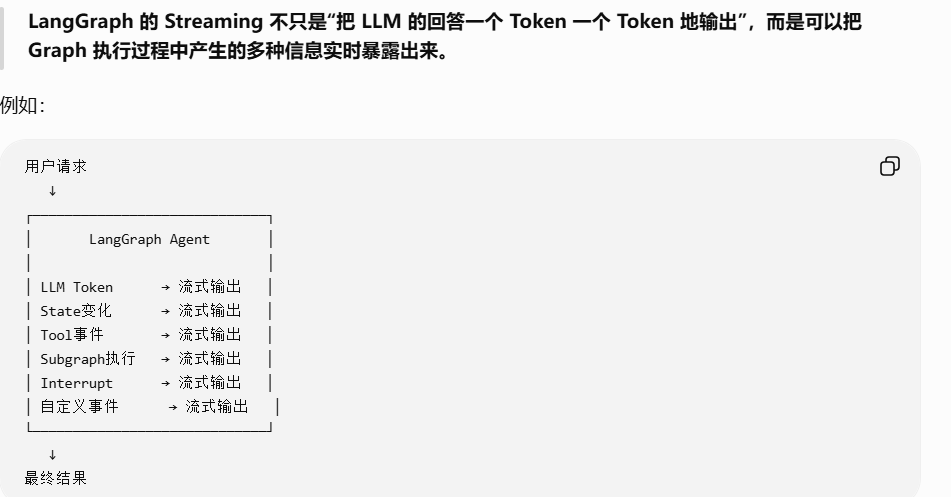

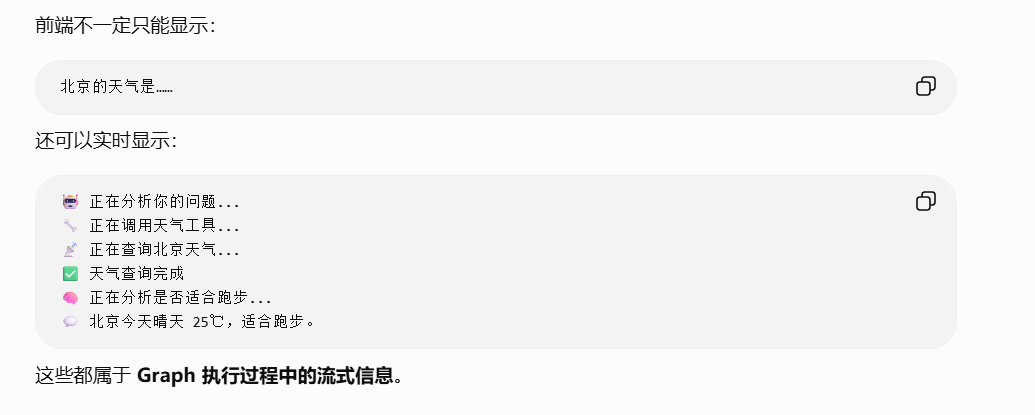


In [30]:
# （2）推荐的stream_events方式（v3）
# 先拿到stream  新版 LangGraph Streaming 把“流式输出”从单一的 Token/Chunk 迭代，升级成了对整个 Graph Run 的多维度流式观察

# 调用 stream_events，并显式指定 version="v3"。
# 返回的不再是简单的 token 迭代器，而是一个 GraphRunStream 对象。
# 这个对象可以同时观察多种事件：消息增量、状态更新、工具调用、生命周期等
stream = agent_graph.stream_events({
    "messages": [{"role": "user", "content": "429和517的平方根是多少?"}],
}, version="v3")

# 真正流式遍历所有Event，其中 method == 'messages' 的就是逐字增量
for event in stream: # 遍历整个 Graph 运行过程中产生的所有协议事
    method = event.get('method')
    if method == 'messages': # 只关心「消息相关」的事件（LLM 输出）
        delta = event['params']['data'][0].get('delta') # 取出内容块的增量（content-block-delta）
        if delta and delta.get('text'): # 取出文本增量（逐字/逐 token）
            print(delta.get('text'), end="", flush=True) # 实时打印，实现打字机效果
# 这就是新版流式的「多维度」体现：同一个 stream 里其实还包含工具调用、状态变化、节点开始/结束等事件，这里只选择了 messages 这一维来做逐字输出。
# 遍历结束后可获取最终完整结果
final_state = stream.output
for m in final_state['messages']:
    m.pretty_print()

print("\n(流式示例结束)")


D:\Langchain\jupyter\.venv\Lib\site-packages\langgraph\pregel\main.py:3708: LangChainBetaWarning: The v3 streaming protocol on Pregel is experimental.
  return self._pregel_stream_v3(
D:\Langchain\jupyter\.venv\Lib\site-packages\langgraph\pregel\main.py:3558: LangChainBetaWarning: The v3 streaming protocol on Pregel is experimental.
  return GraphRunStream(graph_iter, mux)


429的平方根约为 **20.7123**，517的平方根约为 **22.7376**。

具体结果如下：
- √429 ≈ 20.7123
- √517 ≈ 22.7376================================ Human Message =================================

429和517的平方根是多少?
================================== Ai Message ==================================

[{'type': 'tool_call', 'id': 'call_00_ShL1KbZUr1mVIkjvDwws6307', 'name': 'square_root', 'args': {'x': 429}}, {'type': 'tool_call', 'id': 'call_01_p4Xmrux8vIWpJtSW7WU30125', 'name': 'square_root', 'args': {'x': 517}}]
Tool Calls:
  square_root (call_00_ShL1KbZUr1mVIkjvDwws6307)
 Call ID: call_00_ShL1KbZUr1mVIkjvDwws6307
  Args:
    x: 429
  square_root (call_01_p4Xmrux8vIWpJtSW7WU30125)
 Call ID: call_01_p4Xmrux8vIWpJtSW7WU30125
  Args:
    x: 517
================================= Tool Message =================================

20.71231517720798
================================= Tool Message =================================

22.737634001804146
================================== Ai Message ==================================


## 2.9 Interrupts

中断(Interrupts)允许您在特定Node暂停Graph执行，并在继续之前等待外部输入。利用这个特性，就能实现“Human In The Loop”模式，把一些重要决断交给人工来做。

当中断被触发时，LangGraph使用它的 Checkpointer 保存Graph的 State ，并无限期地等待，直到恢复执行。

你可以在Graph的任何Node调用 `interrupt()` 函数来中断工作。该函数接受向调用者显示的任何json可序列化的值。

当您准备好继续时，您可以通过使用 `Command(resume={})，上一个Command是分支选择，都是书写在同一个Command中` 重新调用Graph来恢复执行，而 `resume` 值将成为节点内部 `interrupt()` 调用的返回值。

> 一定要注意：断点恢复必须指定 `thread_id`，它是找到不同会话Checkpointer的关键。

我们还是用之前讲过的邮件助手为例：

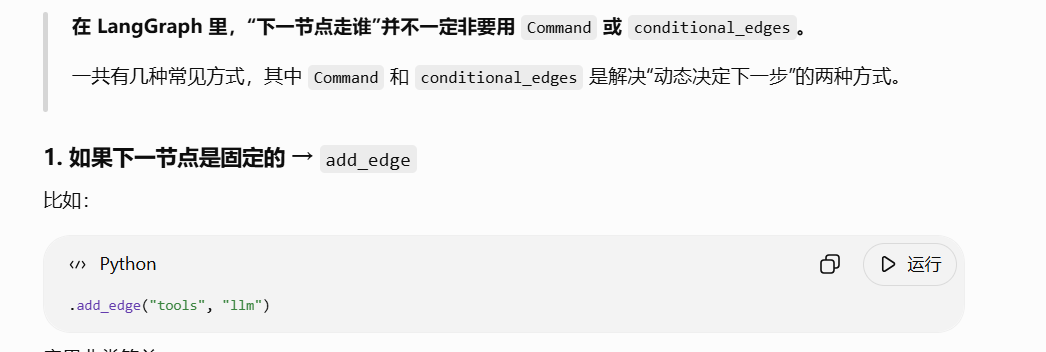


In [31]:
# ====== Step 1: 定义各种工具 ======
@tool
def check_inbox() -> str:
    """Read an email from the given address."""
    # 模拟收件箱邮件
    return str([
        {
            "subject": "周末见个面？",
            "content": """嗨 虎哥，
我下周会去城里，不知道我们有没有机会一起喝杯咖啡？

祝好，简""",
            "from": "jane@itcast.cn",
            "status": "unread"
        },
        {
            "subject": "周五会议",
            "content": """嗨 虎哥，
非常抱歉，我周五的会议无法准时参加了，能不能重新安排个时间？

祝好，小李""",
            "from": "lixiaolong@itcast.cn",
            "status": "checked"
        }
    ])

# 在 send_email 这个工具内部调用 interrupt()，从而把“是否真的发送邮件”的决定交给人
@tool
def send_email(to: str, subject: str, body: str) -> str:
    """Send an response email"""
    human_decision = interrupt({
        "args": {
            "to": to,
            "subject": subject,
            "body": body,
        },
        "confirm": "这是我帮你写的邮件，你觉得如何？",
        "actions": ["reject", "approve", "edit"]
    })
    decision = human_decision.get("action")
    if decision == "approve":
        return f"邮件已发送至 {to} , 主题： {subject} , 内容： {body}"
    elif decision == "reject":
        return f"用户拒绝发送：{human_decision.get('reason')}"
    else:  # 修改邮件了，需要读取邮件内容
        body = human_decision['args']['body']
        return f"邮件已发送至 {to} , 主题： {subject} , 内容： {body}"

# 组成工具数组
tools = [check_inbox, send_email]
# 组成工具名和工具的映射，方便查找工具
tools_by_name = {t.name: t for t in tools}

# ====== Step 2: 定义模型，绑定工具 ======
model = init_chat_model("deepseek-chat")
model_with_tools = model.bind_tools(tools)

print("邮件助手工具定义完成")

邮件助手工具定义完成


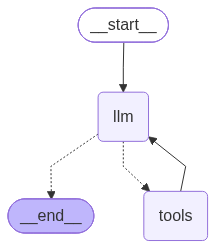

带Interrupts的邮件助手Graph已构建


In [33]:
# ====== Step 3: 定义Node（复用之前的llm_node / tool_node模式） ======
def llm_node(state: MessagesState):
    response = model_with_tools.invoke(state["messages"])
    return {"messages": [response]}

def tool_node(state: MessagesState):
    last_message = state["messages"][-1]
    results = []
    for tool_call in last_message.tool_calls:
        tool = tools_by_name[tool_call["name"]]
        result = tool.invoke(tool_call["args"])
        results.append(ToolMessage(
            content=str(result),
            tool_call_id=tool_call["id"]
        ))
    return {"messages": results}

 # “每次 llm 执行完，就调用 should_continue(state)，然后根据它返回的结果选择下一步。”
def should_continue(state: MessagesState) -> Literal["tools", "__end__"]:
    last_message = state["messages"][-1]
    if hasattr(last_message, 'tool_calls') and last_message.tool_calls:
        return "tools"
    return END

# ====== Step 4: 构建带Checkpointer的Graph（Interrupts必须依赖Checkpointer） ======
interrupt_graph = (
    StateGraph(MessagesState)
    .add_node("llm", llm_node)
    .add_node("tools", tool_node)
    .add_edge(START, "llm")
    .add_conditional_edges("llm", should_continue)
    .add_edge("tools", "llm")
    .compile(checkpointer=InMemorySaver())
)

display(Image(interrupt_graph.get_graph().draw_mermaid_png()))
print("带Interrupts的邮件助手Graph已构建")

使用示例（Human-in-the-loop流程）：

1. 第一次调用会触发 `interrupt`，Graph暂停并返回中断信息。
2. 人工决策后，使用 `Command(resume=...)` 恢复执行。


In [36]:
# 示例调用流程（需要交互）

# 定义会话 ID  告诉 Checkpointer：这是哪一个 Graph 会话
config = {"configurable": {"thread_id": "email-session-1"}}

# 第一次调用：查看收件箱并准备回复（会触发interrupt） 第一次 invoke()：启动 Graph
result = interrupt_graph.invoke(
    {"messages": [HumanMessage(content="帮我看看收件箱，并回复Jane")]},
    config
)
print(result)  # 此时会看到 __interrupt__ 信息

# 人工审批后恢复：人工点击 approve 后，进入第二次 invoke 恢复之前暂停的 Graph
from langgraph.types import Command
result = interrupt_graph.invoke(
    Command(resume={"action": "approve"}),
    config
)
# 把恢复执行后的最终消息结果展示出来
for m in result["messages"]:
    m.pretty_print()

print("Interrupts示例代码已准备（取消注释进行交互测试）")

{'messages': [HumanMessage(content='帮我看看收件箱，并回复Jane', additional_kwargs={}, response_metadata={}, id='552a6159-a3b4-46ec-8bec-b33cfdddfaa0'), AIMessage(content='我来查看一下收件箱。', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 35, 'prompt_tokens': 338, 'total_tokens': 373, 'completion_tokens_details': None, 'prompt_tokens_details': {'audio_tokens': None, 'cache_write_tokens': None, 'cached_tokens': 0}, 'prompt_cache_hit_tokens': 0, 'prompt_cache_miss_tokens': 338}, 'model_provider': 'deepseek', 'model_name': 'deepseek-v4-flash', 'system_fingerprint': 'a26a7955944dc5c60445bff77fac9c8e', 'id': '7f9c4165-7e44-4ca2-b117-d635a2143eb6', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--01a028d3-946f-77f2-a196-068b94c3e043-0', tool_calls=[{'name': 'check_inbox', 'args': {}, 'id': 'call_00_lvGsfvQq01tOG8zkgxgN6826', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 338, 'output_tokens': 35, 'total_tokens': 373, 'in

## 2.10 create_agent揭秘

##### **create_agent 是 LangChain/LangGraph 帮你封装好的“标准 Agent 模板”；StateGraph 是更底层的“流程编排工具”，你可以自己定义节点、边、分支和循环**

至此你可能会发现：手动构建的图和 `create_agent` 行为几乎一样。这不是巧合——`create_agent` 底层就是用 StateGraph 构建的。

### 代码对比

```python
# 你写的代码：
agent = create_agent(
     model="deepseek-chat",
     tools=[get_weather, calculate],
     system_prompt="你是一个有用的助手。",
     checkpointer=InMemorySaver(),
)

# 等同于底层手写的：
agent_graph = (
     StateGraph(MessagesState)
     .add_node("llm", llm_node)
     .add_node("tools", tool_node)
     .add_edge(START, "llm")
     .add_conditional_edges("llm", should_continue, ...)
     .add_edge("tools", "llm")
     .compile(checkpointer=InMemorySaver())
)
```

### create_agent 做了什么？
###### 理解为：create_agent 是一个已经设计好的高级 API  API = 软件对外暴露的“使用接口”。

| 你的参数 | 底层转化 |
|----------|----------|
| model | 绑定到llm_node中 |
| tools | 注册到tool_node中，同时传给 llm.bind_tools() |
| system_prompt | 注入到llm_node的SystemMessage |
| middleware | 在llm_node前后插入before_model/after_model钩子 |
| checkpointer | 传给 graph.compile(checkpointer=...) |
| state_schema | 传给 StateGraph(YourState) |

### 什么时候用哪种？

| 场景 | 推荐方式 |
|------|----------|
| 标准工具调用Agent | create_agent |
| 需要自定义Middleware | create_agent + Middleware |
| RAG、简单检索问答 | create_agent + Middleware |
| 多步骤流水线（检索→分析→总结） | 手动StateGraph |
| 条件分支（审批→执行/驳回） | 手动StateGraph |
| 并行执行（同时调用多个工具/模型） | 手动StateGraph |
| 复杂循环（多轮推理直到满足条件） | 手动StateGraph |
| 子流程嵌套 | 手动StateGraph |

**原则**：能用 `create_agent` 解决的先用它，需要自定义控制流时再用手动Graph。两者不是互斥的——你可以在Graph中嵌套 `create_agent` 作为子节点。

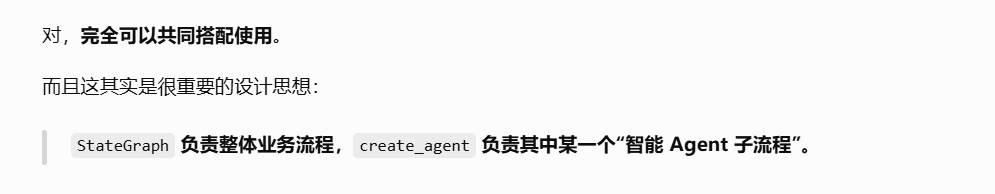


---

## 本节总结

通过本节，我们系统学习了LangGraph的核心概念与从零构建Agent的完整流程：

1. **Node / Edge / State** 三要素及其关系
2. **Reducer** 控制State更新策略（覆盖 vs 累积）
3. **普通边与条件边**，以及用 **Command** 实现动态路由
4. **消息历史 + MessagesState + Checkpointer** 实现会话记忆
5. **ReAct循环**（LLM Node ↔ Tool Node）构建真正的Agent
6. **Runtime Context、节点缓存、失败容错、Streaming、Interrupts** 等进阶能力
7. **create_agent** 与手写Graph的对应关系及选择原则

建议动手把每个代码单元都运行一遍，观察打印输出与图结构，加深理解。
